#### In this notebook i will use the lsm.py to see what happens to a gaussian input and the symbol that is recovvered

In [11]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

print(sys.executable)

c:\Users\henri\Documents\progging\Prosjekt_Master\.venv\Scripts\python.exe


In [12]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd 

from nonlinear.lsm import LSM
from nonlinear.solvers import KdV, Whitham
from linear.help import *


In [13]:
N = 2**6
P = 20
x = np.linspace(-P/2, P/2, N, endpoint=False)
g = np.exp(-x**2)



In [14]:
# plt.plot(x, g);

In [15]:
kdv1 = KdV(P = P, dt = 5e-3, T = 5, u0 = g, save_every=1)
t,u = kdv1.splitStep()

In [16]:
animate_solution_nb(x, u)

In [17]:
lsm = LSM([u], kdv1.dt)
lsm_X = lsm.lsm()



In [18]:
half = N//2
idx = 10
idx_p = N//2 + idx
idx_n = N//2 - idx + 1
ell , n = lsm.fit_symbol(k = np.fft.fftfreq(kdv1.N, d = kdv1.P/kdv1.N)*2*np.pi, idx_range = [idx_n, idx_p], deg = 5)

In [19]:
fit_table(ell, n, part="imag")

,ξ^5,ξ^4,ξ^3,ξ^2,ξ^1,ξ^0
ell,0.000501,-1.370973e-17,0.161118,7.291540e-17,-0.986558,-1.335826e-16
n,-0.000703,-1.958533e-17,0.007692,1.952154e-16,-0.517941,-5.272772e-16


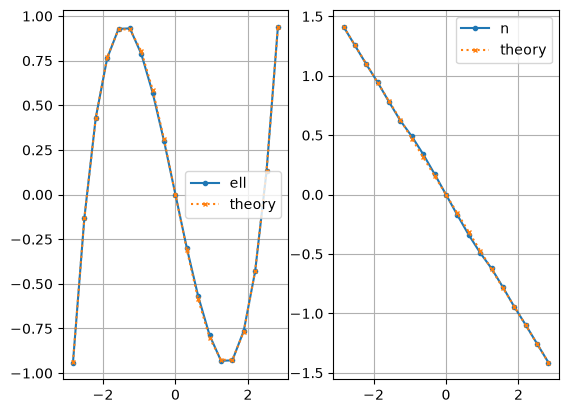

In [20]:
lsm.plot_symbol_fit(k = kdv1.k, idx_range = (idx_n, idx_p), ell_t = lambda k: k**3/6 - k, n_t = lambda k: -0.5*k)